In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error


# 1. Load the dataset.
df = pd.read_csv("/content/drive/MyDrive/uber.csv")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [ ]:
# 2. Remove unnecessary columns and missing values.
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()

# 3. Remove invalid fare values.
df = df[df["fare_amount"] > 0]

In [ ]:
# 4. Detect and remove fare outliers using IQR.
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["fare_amount"] >= lower) & (df["fare_amount"] <= upper)]

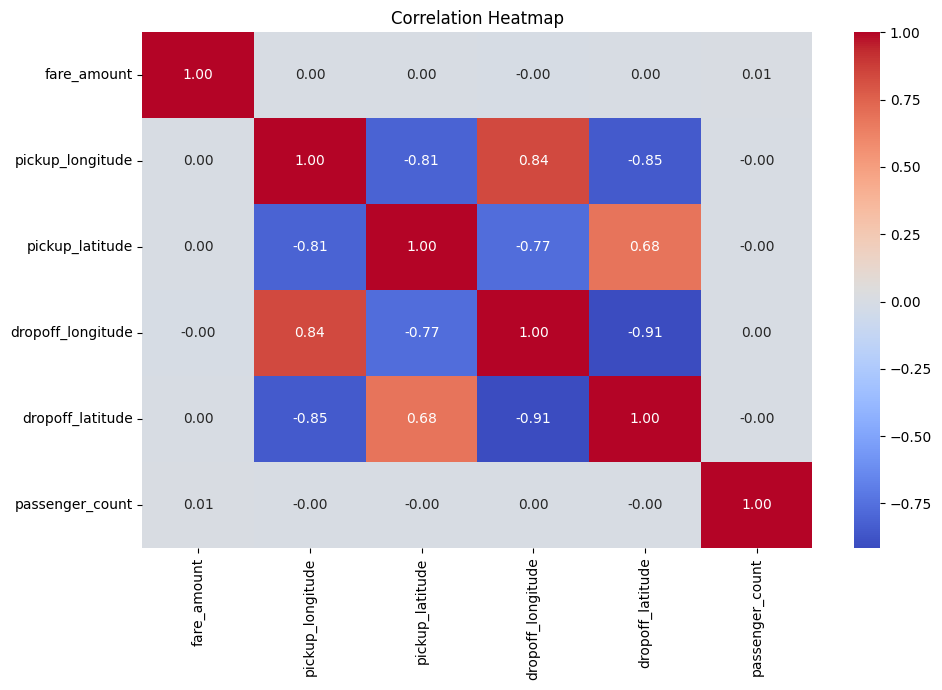

In [ ]:
# 5. Analyze correlations between numerical columns.
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:

# 6. Select available numerical features and target.
target = "fare_amount"
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
feature_columns = [col for col in numeric_columns if col != target]

if not feature_columns:
    raise ValueError("No numeric feature columns found in uber.csv.")

X = df[feature_columns]
y = df[target]

In [ ]:
# 7. Split dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
# 8. Train Linear Regression.
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

In [ ]:
# 9. Train Random Forest Regression.
forest_model = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

In [ ]:
# 10. Evaluate both models using R2 and RMSE.
print("Linear Regression")
print("R2 Score:", round(r2_score(y_test, linear_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, linear_predictions)), 2))

print("\nRandom Forest")
print("R2 Score:", round(r2_score(y_test, forest_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, forest_predictions)), 2))

Linear Regression
R2 Score: 0.0
RMSE: 4.18

Random Forest
R2 Score: 0.71
RMSE: 2.26
